# Telemetry Animation

https://github.com/TracingInsights/2026

https://tif1.tracinginsights.com/introduction

It is advisable to run the notebook in sequence because of all the fig.add_trace() functions used. (Otherwise the visualizations will be a little funky.)

In [23]:
import tif1
import numpy as np
import pandas as pd
import plotly.graph_objects as go

## 1. Get telemetry data

In [43]:
races = tif1.get_events(2025)["EventName"]
print(races[:5])

session = tif1.get_session(2025, "Monaco Grand Prix", "Race")
print(session.drivers_df[:5])

telemetry = (session.get_driver("VER").get_lap(10).telemetry)
telemetry

0       Australian Grand Prix
1          Chinese Grand Prix
2         Japanese Grand Prix
3          Bahrain Grand Prix
4    Saudi Arabian Grand Prix
Name: EventName, dtype: str
  Driver             Team DriverNumber FirstName    LastName TeamColor  \
0    NOR          McLaren            4     Lando      Norris    F47600   
1    LEC          Ferrari           16   Charles     Leclerc    ED1131   
2    PIA          McLaren           81     Oscar     Piastri    F47600   
3    VER  Red Bull Racing            1       Max  Verstappen    4781D7   
4    HAM          Ferrari           44     Lewis    Hamilton    ED1131   

                                         HeadshotUrl  
0  https://media.formula1.com/d_driver_fallback_i...  
1  https://media.formula1.com/d_driver_fallback_i...  
2  https://media.formula1.com/d_driver_fallback_i...  
3  https://media.formula1.com/d_driver_fallback_i...  
4  https://media.formula1.com/d_driver_fallback_i...  


,Date,SessionTime,DriverAhead,DistanceToDriverAhead,Time,RPM,Speed,nGear,Throttle,Brake,...,RelativeDistance,Status,X,Y,Z,AccelerationX,AccelerationY,AccelerationZ,Driver,LapNumber
0,2025-05-25 13:16:30.597,0 days 01:09:30.211000,NaN,18.412222,0 days 00:00:00,10824.383255,272.183332,7,100.0,False,...,7.629400e-08,OnTrack,-7665.201166,-6569.556318,502.015130,1.543211,-7.617551,4.358225,VER,10
1,2025-05-25 13:16:30.776,0 days 01:09:30.390000,NaN,18.412222,0 days 00:00:00.179000,10933.274961,273.674999,7,100.0,False,...,4.158473e-03,OnTrack,-7679.000000,-6329.000000,503.000000,2.916625,-7.784988,1.213026,VER,10
2,2025-05-25 13:16:30.815,0 days 01:09:30.429000,NaN,18.412222,0 days 00:00:00.218000,10957.000000,274.000000,7,100.0,False,...,5.070970e-03,OnTrack,-7680.903811,-6294.488141,503.117187,3.522885,-8.418712,1.213026,VER,10
3,2025-05-25 13:16:31.135,0 days 01:09:30.749000,81,18.412222,0 days 00:00:00.538000,11086.000000,279.000000,7,100.0,False,...,1.264485e-02,OnTrack,-7680.860170,-6173.986338,503.026761,3.908687,-9.838381,11.146469,VER,10
4,2025-05-25 13:16:31.235,0 days 01:09:30.849000,81,17.967778,0 days 00:00:00.638000,10846.625000,280.250000,7,37.5,False,...,1.504082e-02,OnTrack,-7674.000000,-6080.000000,503.000000,-0.845288,-11.025714,19.112457,VER,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
570,2025-05-25 13:17:49.275,0 days 01:10:48.889000,81,29.040833,0 days 00:01:18.678000,11279.412106,263.475002,6,100.0,False,...,9.885417e-01,OnTrack,-7642.000000,-6925.000000,502.000000,5.651396,-5.835759,-4.323878,VER,10
571,2025-05-25 13:17:49.376,0 days 01:10:48.990000,81,28.956667,0 days 00:01:18.779000,10657.000000,266.000000,7,100.0,False,...,9.908245e-01,OnTrack,-7648.859450,-6827.571872,501.723955,5.205040,-4.644916,-4.397098,VER,10
572,2025-05-25 13:17:49.536,0 days 01:10:49.150000,81,28.778889,0 days 00:01:18.939000,10727.000000,268.000000,7,100.0,False,...,9.944621e-01,OnTrack,-7660.213157,-6647.922861,501.864330,4.433436,-3.047421,-5.950078,VER,10
573,2025-05-25 13:17:49.615,0 days 01:10:49.229000,81,28.778889,0 days 00:01:19.018000,10783.616713,269.316668,7,100.0,False,...,9.962736e-01,OnTrack,-7665.000000,-6570.000000,502.000000,4.371354,-2.482466,-8.541367,VER,10


In [25]:
telemetry = telemetry[["Time",  "X", "Y"]]
telemetry

,Time,X,Y
0,0 days 00:00:00,-7665.201166,-6569.556318
1,0 days 00:00:00.179000,-7679.000000,-6329.000000
2,0 days 00:00:00.218000,-7680.903811,-6294.488141
3,0 days 00:00:00.538000,-7680.860170,-6173.986338
4,0 days 00:00:00.638000,-7674.000000,-6080.000000
...,...,...,...
570,0 days 00:01:18.678000,-7642.000000,-6925.000000
571,0 days 00:01:18.779000,-7648.859450,-6827.571872
572,0 days 00:01:18.939000,-7660.213157,-6647.922861
573,0 days 00:01:19.018000,-7665.000000,-6570.000000


## 2. Get circuit image

In [26]:
circuit = session.get_circuit_info()
track = circuit.track
corners = circuit.corners

print(track)
print(type(track))
print(corners)
type(corners)

          X       Y      Time
0   -7661.0 -6619.0   993.039
1   -7666.0 -6556.0   993.130
2   -7674.0 -6428.0   993.310
3   -7674.0 -6412.0   993.332
4   -7681.0 -6300.0   993.490
..      ...     ...       ...
678 -7642.0 -6924.0  1082.830
679 -7648.0 -6838.0  1083.012
680 -7651.0 -6804.0  1083.090
681 -7657.0 -6706.0  1083.252
682 -7662.0 -6636.0  1083.343

[683 rows x 3 columns]
<class 'pandas.DataFrame'>
              X            Y  Number Letter       Angle     Distance
0  -7381.106934 -4719.949219       1         140.384631   186.471184
1  -3634.549072 -3769.346436       2         103.015117   581.687735
2  -2275.649414 -3071.900879       3         168.949842   744.149504
3  -2745.113281 -1956.109497       4        -174.396257   873.202140
4  -1422.224854  -197.893692       5          76.191057  1102.762534
5   -797.246765 -1127.089111       6         -85.862753  1222.924327
6  -1016.884705  -477.596558       7         -14.461416  1304.183481
7   -271.229309  -251.078979       8 

pandas.DataFrame

In [27]:
# first viz using the same package also used for the waterfall chart
fig = go.Figure()

fig.add_trace(go.Scatter(x=track["X"], y=track["Y"], mode="lines",))

fig.show()

In [28]:
fig = go.Figure()

fig.add_trace(go.Scatter(x=track["X"], y=track["Y"], mode="lines",))

# both axis should have the same length in order to get a distortion-free image
fig.update_yaxes(scaleanchor="x", scaleratio=1)
# can also square the whole plot
fig.update_layout(width=750, height=750)

fig.show()

## 3. First Try

In [29]:
# To be safe from special events during a race that would distort the visualization (e.g. safety car), I just use the fastest lap of the driver.
fastest_lap = session.get_driver("VER").get_fastest_lap_tel()[["Time", "X", "Y"]].dropna()
fastest_lap

,Time,X,Y
0,0 days 00:00:00,-7662.872842,-6590.298846
1,0 days 00:00:00.021000,-7665.071820,-6555.732496
2,0 days 00:00:00.193000,-7678.000000,-6352.000000
3,0 days 00:00:00.341000,-7681.880552,-6289.525835
4,0 days 00:00:00.473000,-7681.000000,-6247.000000
...,...,...,...
553,0 days 00:01:13.813000,-7647.000000,-6851.000000
554,0 days 00:01:13.821000,-7647.507207,-6843.285002
555,0 days 00:01:14.052000,-7664.000000,-6575.000000
556,0 days 00:01:14.141000,-7669.180349,-6489.125374


In [30]:
# place all data points on the plot
fig.add_trace(go.Scatter(x = fastest_lap["X"], y = fastest_lap["Y"], mode = "markers")) # somehow everything is a "trace" in potly


https://plotly.com/python/animations/
Plotly uses frames for animation. 

Problem is that frame duration is the same for every frame (i.e. position of driver). Since I want the position to match with the real times (to see acceleration and braking), I need to find a different solution. 

The simplest approach is to use np.interp() to interpolate the drivers positions for regular time intervals. 


In [31]:
# remove above trace
fig.data = fig.data[:-1]

# add first point of the lap to the plot ([0])
fig.add_trace(go.Scatter(x = [fastest_lap["X"][0]], y = [fastest_lap["Y"][0]], mode = "markers")) # the coordinates are not allowed to be floats -> use list

In [32]:
# define which trace (i.e. NOT the whole circuit trace, but only the driver position) should be updated in the next animation frame 
driver_trace = len(fig.data) - 1 

# add animation
fig.frames = [go.Frame(data=[go.Scatter(x = [row["X"]], y = [row["Y"]])], traces=[driver_trace]) for _, row in fastest_lap.iterrows()] # .iterrows() iterates through the rows of the df it outputs a tuple (column, row)

# add playback controls - AI generated code
fig.update_layout(updatemenus=[dict(type="buttons", buttons=[dict(label="Play", method="animate", args=[None, {"frame": {"duration": 100, "redraw": False}, "transition": {"duration": 0}, "fromcurrent": True}]),
                                                             dict(label="Pause", method="animate", args=[[None], {"mode": "immediate", "frame": {"duration": 0}, "transition": {"duration": 0}}])])])

fig.show()

The visualization does not look to bad even without interpolation. Maybe the coordinates are collected regularly. -> Check this assumption with time stamps: 

count    557.000000
mean     133.267504
std       85.979472
min        8.000000
25%       68.000000
50%      130.000000
75%      190.000000
max      600.000000
Name: Time, dtype: float64


<Axes: >

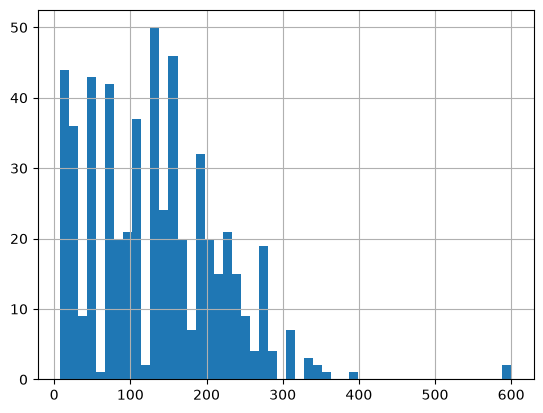

In [33]:
timestamp_diff = fastest_lap["Time"].sort_values().diff().dt.total_seconds() * 1000

print(timestamp_diff.describe())
timestamp_diff.hist(bins=50)

## 4. Second Try: Interpolation

In [34]:
# transform data in numpy format for interpolation using numpy

time = fastest_lap.sort_values("Time").drop_duplicates("Time") # drop duplicates to be safe
print(time)

# "standardize" timestamps to numpy seconds starting at zero
time = time["Time"].dt.total_seconds().to_numpy()
time = time - time[0]
time[:10]

                      Time            X            Y
0          0 days 00:00:00 -7662.872842 -6590.298846
1   0 days 00:00:00.021000 -7665.071820 -6555.732496
2   0 days 00:00:00.193000 -7678.000000 -6352.000000
3   0 days 00:00:00.341000 -7681.880552 -6289.525835
4   0 days 00:00:00.473000 -7681.000000 -6247.000000
..                     ...          ...          ...
553 0 days 00:01:13.813000 -7647.000000 -6851.000000
554 0 days 00:01:13.821000 -7647.507207 -6843.285002
555 0 days 00:01:14.052000 -7664.000000 -6575.000000
556 0 days 00:01:14.141000 -7669.180349 -6489.125374
557 0 days 00:01:14.230000 -7673.359466 -6419.686869

[558 rows x 3 columns]


array([0.   , 0.021, 0.193, 0.341, 0.473, 0.541, 0.713, 0.953, 0.981,
       1.193])

In [35]:
# interpolating to x fps
fps = 20
time_interp = np.arange(0, time[-1], 1 / fps) # np.arange(start, stop, step)
x_interp = np.interp(time_interp, time, fastest_lap["X"])
y_interp = np.interp(time_interp, time, fastest_lap["Y"]) 

Create the figure again from scratch:

In [36]:
fig = go.Figure()

# Circuit
fig.add_trace(go.Scatter(x=track["X"], y=track["Y"], mode="lines"))

# Driver at starting position
fig.add_trace(go.Scatter(x=[x_interp[0]], y=[y_interp[0]], mode="markers"))

# Keep original proportions
fig.update_yaxes(scaleanchor="x", scaleratio=1)
fig.update_layout(width=750, height=750)

fig.show()

Only thing I must adjust in the plot is to set the duration according to the fps. In the interpolation I created 20 fps -> new position every 0.05s = 50ms. This means I need to change the frame every 50 milliseconds.

NB: When rendering is slow the frame duration will adjust to the slower rendering.

In [37]:
driver_trace = len(fig.data) - 1 

# add animation
fig.frames = [go.Frame(data=[go.Scatter(x=[x], y=[y])], traces=[driver_trace]) for x, y in zip(x_interp, y_interp)] # using pairs from zip let's me omit .iterrow() to iterate over a whole dataframe

# the duration must match the fps
fig.update_layout(updatemenus=[dict(type="buttons", buttons=[dict(label="Play", method="animate", args=[None, {"frame": {"duration": 1000 / fps, "redraw": False}, "transition": {"duration": 0}, "fromcurrent": True}]),
                                                             dict(label="Pause", method="animate", args=[[None], {"mode": "immediate", "frame": {"duration": 0}, "transition": {"duration": 0}}])])])

fig.show()

## 5. Create function

In [38]:
def telemetry_viz(year, circuit, driver, fps=20):

    # 1. Load data
    session = tif1.get_session(year, circuit, "Race")
    track = session.get_circuit_info().track

    telemetry = (session.get_driver(driver).get_fastest_lap_tel()[["Time", "X", "Y"]].dropna().sort_values("Time").drop_duplicates("Time"))

    # 2. Prepare time for interpolation
    time = telemetry["Time"].dt.total_seconds().to_numpy()
    time = time - time[0]

    # 3. Interpolate
    time_interp = np.arange(0, time[-1], 1 / fps)
    x_interp = np.interp(time_interp, time, telemetry["X"])
    y_interp = np.interp(time_interp, time, telemetry["Y"])

    # 4. Create figure
    fig = go.Figure()

    fig.add_trace(go.Scatter(x=track["X"], y=track["Y"], mode="lines", name="Circuit"))

    fig.add_trace(go.Scatter(x=[x_interp[0]], y=[y_interp[0]], mode="markers", name=driver))

    fig.update_yaxes(scaleanchor="x", scaleratio=1)
    fig.update_layout(width=750, height=750)

    # 5. Animation 
    driver_trace = len(fig.data) - 1

    fig.frames = [go.Frame(data=[go.Scatter(x=[x], y=[y])], traces=[driver_trace]) for x, y in zip(x_interp, y_interp)] 

    # 6. Playback controls (AI generated)
    fig.update_layout(updatemenus=[dict(type="buttons", buttons=[
    dict(label="Play", method="animate", args=[None, {"frame": {"duration": 1000 / fps, "redraw": False}, "transition": {"duration": 0}, "fromcurrent": True}]),
    dict(label="Pause", method="animate", args=[[None], {"frame": {"duration": 0, "redraw": False}, "transition": {"duration": 0}, "mode": "immediate"}])
    ])])

    return fig

In [39]:
telemetry_viz(2026, "São Paulo Grand Prix", "ANT", fps=20)

### Make viz good looking (AI-generated)

In [40]:
def telemetry_viz(year, circuit, driver, fps=20):

    # F1 DESIGN (AI-generated)
    BACKGROUND = "#101014"
    GRID = "#303038"
    WHITE = "#FFFFFF"
    MUTED = "#AAAAAA"
    RED = "#E5484D"

    # 1. Load data
    session = tif1.get_session(year, circuit, "Race")
    track = session.get_circuit_info().track

    telemetry = (session.get_driver(driver).get_fastest_lap_tel()[["Time", "X", "Y"]].dropna().sort_values("Time").drop_duplicates("Time"))

    # 2. Prepare time for interpolation
    time = telemetry["Time"].dt.total_seconds().to_numpy()
    time = time - time[0]

    # 3. Interpolate
    time_interp = np.arange(0, time[-1], 1 / fps)
    x_interp = np.interp(time_interp, time, telemetry["X"])
    y_interp = np.interp(time_interp, time, telemetry["Y"])

    # 4. Create figure
    fig = go.Figure()

    fig.add_trace(go.Scatter(x=track["X"], y=track["Y"], mode="lines", name="Circuit", line=dict(color="#666674", width=5), hoverinfo="skip"))

    fig.add_trace(go.Scatter(x=[x_interp[0]], y=[y_interp[0]], mode="markers", name=driver, marker=dict(color=RED, size=13, line=dict(color=WHITE, width=2)), hoverinfo="skip"))

    # F1 styling  (AI-generated)
    fig.update_layout(
        title=dict(
            text=f"<b>F1 / LAP TELEMETRY</b><br><span style='font-size:14px;color:{MUTED}'>{year} {circuit} | {driver} | Fastest Lap</span>",
            font=dict(size=23, color=WHITE),
            x=0.04, y=0.97, xanchor="left", yanchor="top"
        ),
        template="plotly_dark",
        paper_bgcolor=BACKGROUND,
        plot_bgcolor=BACKGROUND,
        font=dict(family="Arial", color=WHITE, size=13),
        width=750, height=750,
        margin=dict(l=40, r=40, t=110, b=100),
        showlegend=False,
        hovermode=False
    )

    fig.update_xaxes(visible=False)
    fig.update_yaxes(visible=False, scaleanchor="x", scaleratio=1)

    # 5. Animation
    driver_trace = len(fig.data) - 1

    fig.frames = [go.Frame(data=[go.Scatter(x=[x], y=[y])], traces=[driver_trace]) for x, y in zip(x_interp, y_interp)]

    # 6. Playback controls (AI generated)
    fig.update_layout(updatemenus=[dict(
        type="buttons", direction="left", showactive=False,
        x=0.5, xanchor="center", y=-0.05, yanchor="top",
        bgcolor="#202027", bordercolor=GRID, font=dict(color=WHITE, size=13),
        buttons=[
            dict(label="▶ Play", method="animate", args=[None, {"frame": {"duration": 1000 / fps, "redraw": False}, "transition": {"duration": 0}, "fromcurrent": True}]),
            dict(label="Ⅱ Pause", method="animate", args=[[None], {"frame": {"duration": 0, "redraw": False}, "transition": {"duration": 0}, "mode": "immediate"}])
        ]
    )])

    return fig

In [41]:
telemetry_viz(2026, "São Paulo Grand Prix", "ANT", fps=20)